In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import wandb
from datasets import get_dataset
import torch
from utils import save_run, load_run
from funcs import train_epoch, val_epoch, test_epoch
from weight_inits import init_timesformer
from torch.utils.data import DataLoader
from models.vivit_custom.utils.scheduler import WarmupCosineSchedule
from transforms import get_transforms, Div255, SplitEqually

from constants import get_classes
from transformers import TimesformerConfig, TimesformerForVideoClassification
from transformers import ViTForImageClassification
from pytorchvideo.transforms import MixUp
import torch
from torchvision.transforms.v2 import (
    ScaleJitter,
    RandAugment,
    RandomCrop,
    Compose,
    ColorJitter,
    RandomHorizontalFlip,
    Normalize,
    RandomApply,
    UniformTemporalSubsample,
    CenterCrop,
    Lambda,
)
from pytorchvideo.transforms import UniformTemporalSubsample, ApplyTransformToKey

C:\Users\Wojtek\AppData\Roaming\Python\Python310\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
config = {
    "base_learning_rate": 0.001,
    "label_smoothing": 0.2,
    "epochs": 10,
    "frames": 8,
    "val_epochs": 1,
    "batch_size": 20,
    "weight_decay": 1e-5,
    "load_run": False,
    "init_vit": True,
    "vit_base_size": "tiny",
    "cosine_schedule": True,
    "augmentations": True,
    "advanced_augmentations": True,
    "mixup": True,
    "mixup_alpha": 0.2,
    "dataset": "ucf101",
}

In [ ]:
CLASSES_LIST = get_classes(config["dataset"])

ds_transform_train, ds_transform_valid, test_transform = get_transforms(config, CLASSES_LIST, config['dataset'])

dataset_train, dataset_valid, dataset_test, num_labels = get_dataset(
    config["dataset"], ds_transform_train, ds_transform_valid, test_transform, lazy=False
)

#training_loader = DataLoader(dataset=dataset_train, batch_size=8, shuffle=True)

In [ ]:
transform = Compose(
    transforms=[
        UniformTemporalSubsample(num_samples=config["frames"], temporal_dim=0),
        RandomHorizontalFlip(p=0.5),
        #ScaleJitter(target_size=(240, 320), scale_range=(0.85, 1.33)),
        RandomCrop(size=(224, 224), pad_if_needed=True, fill=128),
        RandomApply(p=1, transforms=[ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.1)]),
        # RandAugment(num_ops=2, magnitude=10, fill=128),
        Div255(),
        Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ]
)

In [77]:
from utils import show_img_chw

In [78]:
dataset_valid.transform = transform

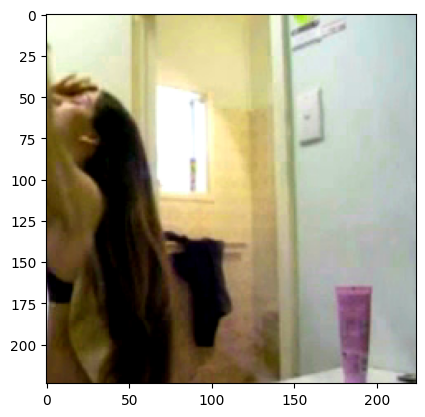

In [83]:
show_img_chw(dataset_valid[0][0][0], denormalize=True)

In [3]:
import wandb
from datasets import get_dataset
import torch
import random
import numpy as np
from utils import load_run, show_img_chw
from funcs import train_epoch, val_epoch, test_epoch
from weight_inits import init_timesformer
from models.vivit_custom.utils.scheduler import WarmupCosineSchedule
from transforms import get_transforms

from constants import get_classes
from vit_configs import get_vit_config
from loaders import get_loaders
from transformers import TimesformerConfig, TimesformerForVideoClassification
from transformers import ViTForImageClassification
from pytorchvideo.transforms import MixUp
from torch.utils.data import Subset
import matplotlib.pyplot as plt

/opt/conda/envs/msc/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
SEED = 0
torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

In [58]:
CLASSES_LIST = get_classes(config["dataset"])
ds_transform_train, ds_transform_valid, test_transform = get_transforms(config, CLASSES_LIST, config["dataset"])

dataset_train, dataset_valid, dataset_test, num_labels = get_dataset(
    config["dataset"], ds_transform_train, ds_transform_valid, test_transform, lazy=True
)

/opt/conda/envs/msc/lib/python3.12/site-packages/torchvision/datasets/video_utils.py:219: UserWarning: There aren't enough frames in the current video to get a clip for the given clip length and frames between clips. The video (and potentially others) will be skipped.
  warnings.warn(


In [59]:
import torchvision
dataset_train.transform = torchvision.transforms.Compose([])

In [74]:
t = Subset(dataset_train, [0, 1, 2, 1000])

In [61]:
training_loader, validation_loader, test_loader = get_loaders(
    dataset_train, dataset_valid, dataset_test, SEED, 3
)

t_loader, validation_loader, test_loader = get_loaders(
    t, dataset_valid, dataset_test, SEED, 3
)

/opt/conda/envs/msc/lib/python3.12/site-packages/torchvision/io/video.py:197: UserWarning: The pts_unit 'pts' gives wrong results. Please use pts_unit 'sec'.
  warnings.warn("The pts_unit 'pts' gives wrong results. Please use pts_unit 'sec'.")


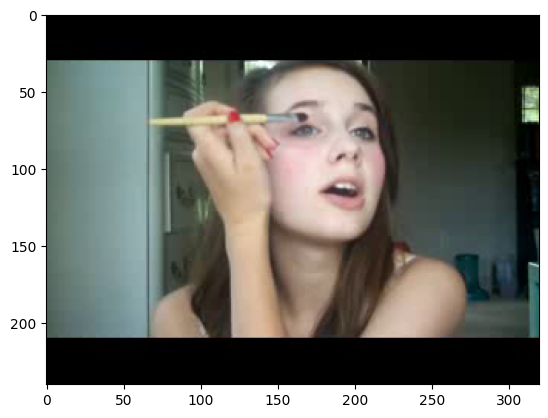

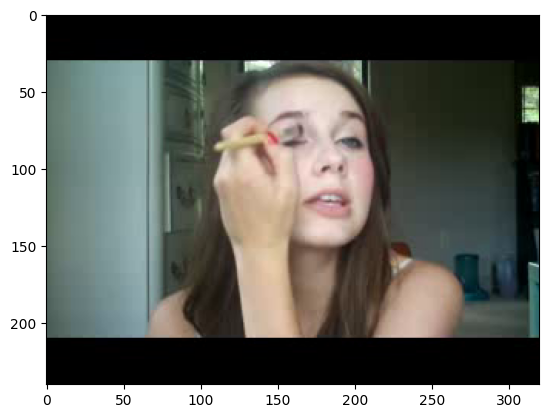

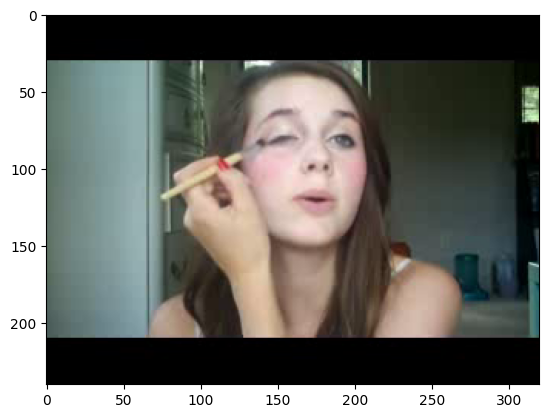

In [63]:
cnt = 0
for i, l in t_loader:
    for img in i:
        show_img_chw(img[0], denormalize=0)
        plt.show()
    cnt += 1
    break

/opt/conda/envs/msc/lib/python3.12/site-packages/torchvision/io/video.py:197: UserWarning: The pts_unit 'pts' gives wrong results. Please use pts_unit 'sec'.
  warnings.warn("The pts_unit 'pts' gives wrong results. Please use pts_unit 'sec'.")


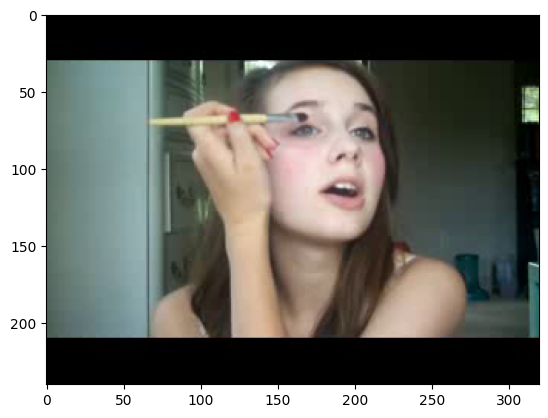

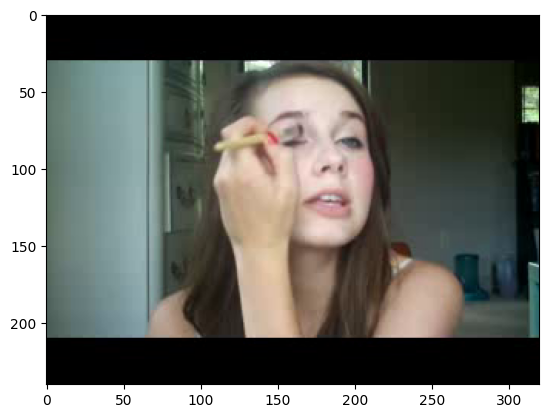

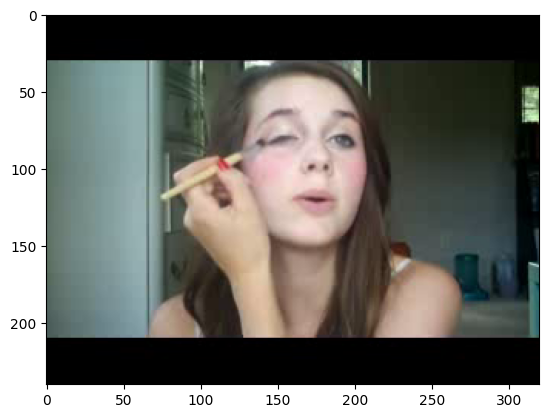

In [64]:
cnt = 0
for i, l in training_loader:
    for img in i:
        show_img_chw(img[0], denormalize=0)
        plt.show()
    cnt += 1
    break